# Etapa 3 — Ajuste do Pipeline e Reavaliação
## Cozinha Consciente — Sistema de Recomendação Híbrido de Receitas

Este notebook documenta como os resultados preliminares (notebook 02) foram analisados e como o
pipeline foi ajustado. Regra do experimento: **todas as escolhas são feitas no conjunto de
validação; o conjunto de teste só é usado na reavaliação final.**

Para reexecutar o ajuste completo (≈ 3 min): `python -m src.tuning`. Este notebook lê as tabelas
já geradas, salvas em `docs/resultados_etapa3/`.

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RES = Path("../docs/resultados_etapa3")
FIG = RES / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
cfg = json.loads((RES / "tuning_melhor_config.json").read_text(encoding="utf-8"))
cfg

{'SVD_FACTORS': 32,
 'ITEMKNN_NEIGHBORS': 500,
 'HYBRID_WEIGHTS': {'pop': 0.6, 'itemknn': 0.1, 'svd': 0.1, 'content': 0.2},
 'HYBRID_NORM': 'zscore',
 'HEALTH_LAMBDA': 0.35,
 'criterio_lambda': 'maior lambda com perda relativa de NDCG@10 <= 10% na validação',
 'casos_validacao': 16040,
 'casos_teste': 16039}

## 1. Análise dos resultados preliminares
A revisão da prova de conceito apontou quatro pontos:

1. **Protocolo de avaliação.** O item relevante ficava na posição 0 dos candidatos, e os empates de
   escore o favoreciam. A tabela abaixo mostra o efeito (HitRate@10 no teste):

In [2]:
pd.DataFrame({
    "HitRate@10 (protocolo antigo)":     {"Popularidade": 0.5073, "ItemKNN (200 viz.)": 0.6654, "SVD (64 fatores)": 0.3520},
    "HitRate@10 (posição aleatória)":    {"Popularidade": 0.5072, "ItemKNN (200 viz.)": 0.1801, "SVD (64 fatores)": 0.3494},
})

,HitRate@10 (protocolo antigo),HitRate@10 (posição aleatória)
Popularidade,0.5073,0.5072
ItemKNN (200 viz.),0.6654,0.1801
SVD (64 fatores),0.3520,0.3494


   O ItemKNN parecia o melhor modelo (0,665) apenas por causa dos empates em zero; corrigido, é o pior.
2. **Hiperparâmetros** de SVD (64 fatores) e ItemKNN (200 vizinhos) definidos sem validação.
3. **Pesos do híbrido** (0,5/0,3/0,2) definidos a priori e sem componente de popularidade.
4. **Escolha de λ** (0,30) sem critério explícito.

## 2. Ajuste de hiperparâmetros dos modelos (validação)

In [3]:
comp = pd.read_csv(RES / "tuning_componentes_validacao.csv", index_col=0)
comp[["HitRate@10", "NDCG@10", "Cobertura_catalogo"]]

,HitRate@10,NDCG@10,Cobertura_catalogo
modelo,,,
pop,0.5112,0.3317,0.1724
content,0.2294,0.1218,0.7137
svd_32,0.3940,0.2599,0.6441
svd_64,0.3542,0.2340,0.7380
svd_128,0.3257,0.2119,0.8093
svd_256,0.3024,0.1948,0.8571
knn_50,0.1579,0.0926,0.9813
knn_100,0.1727,0.1003,0.9767
knn_200,0.1906,0.1092,0.9662


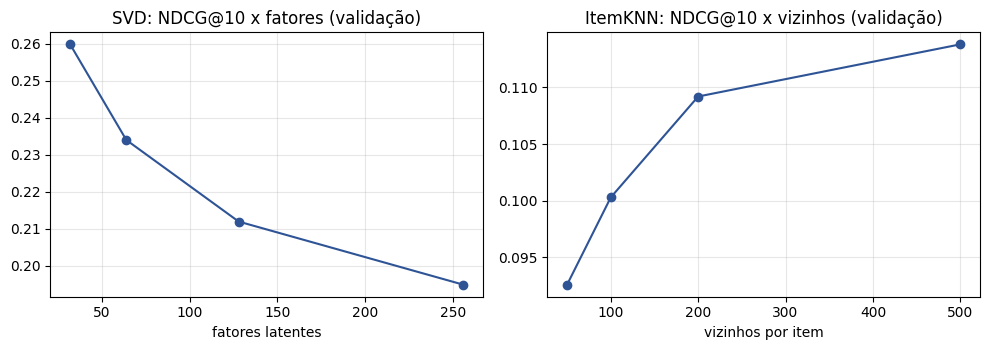

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
svd = comp.loc[[i for i in comp.index if i.startswith("svd_")], "NDCG@10"]
knn = comp.loc[[i for i in comp.index if i.startswith("knn_")], "NDCG@10"]
ax[0].plot([int(i.split("_")[1]) for i in svd.index], svd.values, marker="o", color="#2E5496")
ax[0].set_title("SVD: NDCG@10 x fatores (validação)"); ax[0].set_xlabel("fatores latentes")
ax[1].plot([int(i.split("_")[1]) for i in knn.index], knn.values, marker="o", color="#2E5496")
ax[1].set_title("ItemKNN: NDCG@10 x vizinhos (validação)"); ax[1].set_xlabel("vizinhos por item")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "ajuste_componentes.png", dpi=150); plt.show()

**Leitura:** o SVD melhora com *menos* fatores (32 foi o melhor da grade) e o ItemKNN melhora com
*mais* vizinhos (500 foi o melhor). Ambos estão nas bordas da grade testada, então há espaço para
explorar valores fora dela (ex.: 16 fatores; 1000 vizinhos, que exige mais memória).

## 3. Ajuste dos pesos do híbrido e da normalização (validação)
Grade com passo 0,1 sobre quatro componentes (popularidade, ItemKNN, SVD, conteúdo) e duas
normalizações por usuário (min-max e z-score): 572 configurações.

In [5]:
hib = pd.read_csv(RES / "tuning_hibrido_validacao.csv")
hib.head(8)

,norm,w_pop,w_itemknn,w_svd,w_content,NDCG@10,HitRate@10
0,zscore,0.6,0.1,0.1,0.2,0.3437,0.5316
1,zscore,0.5,0.1,0.1,0.3,0.3435,0.5249
2,zscore,0.6,0.0,0.1,0.3,0.3424,0.5268
3,zscore,0.7,0.0,0.1,0.2,0.3423,0.5314
4,zscore,0.5,0.0,0.2,0.3,0.3419,0.5246
5,zscore,0.6,0.1,0.0,0.3,0.3417,0.5244
6,zscore,0.6,0.0,0.2,0.2,0.3415,0.5281
7,zscore,0.4,0.1,0.2,0.3,0.3415,0.5180


**Leitura:** o melhor híbrido usa z-score e dá 60% do peso à popularidade, 20% ao conteúdo e 10% a
cada modelo colaborativo. Os componentes personalizados contribuem pouco sozinhos, mas a combinação
supera a popularidade pura.

## 4. Compromisso relevância × saudabilidade (escolha de λ)
Critério definido antes de olhar o teste: **maior λ cuja perda relativa de NDCG@10 na validação seja
de no máximo 10%** em relação a λ = 0.

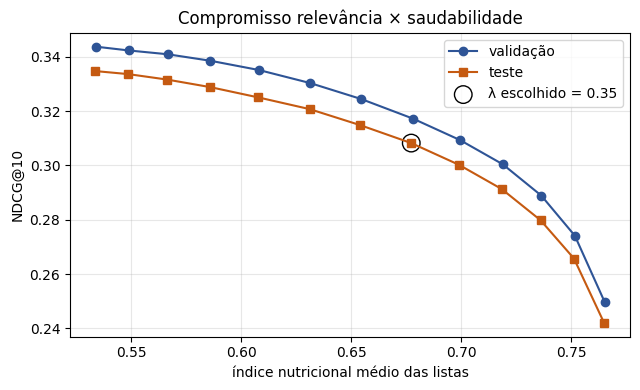

,lambda,HitRate@10,NDCG@10,IndiceNutricional@10
0,0.00,0.5316,0.3437,0.5338
1,0.05,0.5280,0.3423,0.5488
2,0.10,0.5248,0.3409,0.5665
3,0.15,0.5187,0.3385,0.5860
4,0.20,0.5105,0.3351,0.6080
5,0.25,0.4989,0.3303,0.6313
6,0.30,0.4846,0.3244,0.6546
7,0.35,0.4686,0.3172,0.6781
8,0.40,0.4522,0.3093,0.6995
9,0.45,0.4349,0.3004,0.7189


In [6]:
cv = pd.read_csv(RES / "tuning_curva_lambda_valid.csv")
ct = pd.read_csv(RES / "tuning_curva_lambda_test.csv")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(cv["IndiceNutricional@10"], cv["NDCG@10"], marker="o", label="validação", color="#2E5496")
ax.plot(ct["IndiceNutricional@10"], ct["NDCG@10"], marker="s", label="teste", color="#C55A11")
sel = ct[ct["lambda"] == cfg["HEALTH_LAMBDA"]].iloc[0]
ax.scatter([sel["IndiceNutricional@10"]], [sel["NDCG@10"]], s=160, facecolors="none",
           edgecolors="black", label=f"λ escolhido = {cfg['HEALTH_LAMBDA']}")
ax.set_xlabel("índice nutricional médio das listas"); ax.set_ylabel("NDCG@10")
ax.set_title("Compromisso relevância × saudabilidade"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "curva_compromisso.png", dpi=150); plt.show()
cv[["lambda", "HitRate@10", "NDCG@10", "IndiceNutricional@10"]]

## 5. Reavaliação final no conjunto de teste (configuração inicial × ajustada)

In [7]:
final = pd.read_csv(RES / "tuning_comparacao_teste.csv", index_col=0)
final[["HitRate@10", "NDCG@10", "MAP@10", "Cobertura_catalogo", "Vies_popularidade", "IndiceNutricional@10"]]

,HitRate@10,NDCG@10,MAP@10,Cobertura_catalogo,Vies_popularidade,IndiceNutricional@10
modelo,,,,,,
Popularidade,0.5072,0.3277,0.2722,0.1718,0.0681,0.5258
ItemKNN inicial (200 viz.),0.1801,0.1003,0.0761,0.9657,0.0210,0.5416
ItemKNN ajustado (500 viz.),0.2000,0.1087,0.0812,0.9389,0.0223,0.5424
SVD inicial (64 fatores),0.3494,0.2282,0.1910,0.7381,0.0421,0.5391
SVD ajustado (32 fatores),0.3799,0.2502,0.2103,0.6444,0.0476,0.5362
Conteudo (TF-IDF),0.2128,0.1095,0.0786,0.7135,0.0197,0.5678
Hibrido inicial (lambda=0),0.3530,0.2171,0.1757,0.8634,0.0373,0.5453
Hibrido inicial (lambda=0.30),0.3315,0.2062,0.1679,0.8103,0.0355,0.6261
Hibrido ajustado (lambda=0),0.5185,0.3347,0.2778,0.4816,0.0642,0.5337


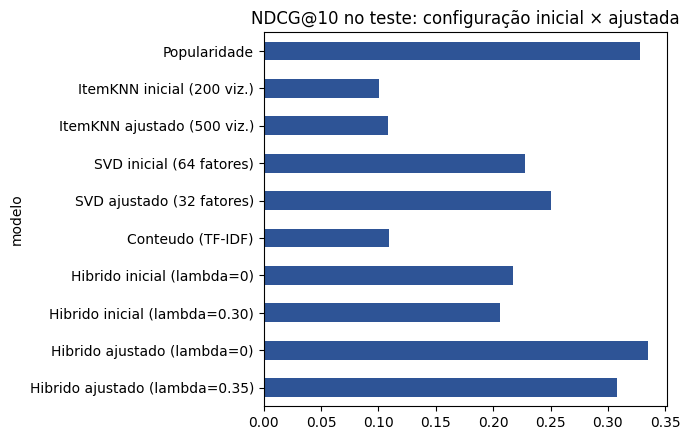

In [8]:
ax = final["NDCG@10"].plot(kind="barh", color="#2E5496", figsize=(7, 4.5))
ax.set_title("NDCG@10 no teste: configuração inicial × ajustada"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(FIG / "comparacao_final.png", dpi=150); plt.show()

## 6. Discussão

- **Ganho do ajuste.** SVD: NDCG 0,228 → 0,250 (+9,6%) com 32 fatores; ItemKNN: 0,100 → 0,109 (+8,4%)
  com 500 vizinhos; híbrido sem reordenação: 0,217 → 0,335 (+54%), em grande parte por incluir a
  popularidade e escolher os pesos na validação.
- **Híbrido × popularidade.** O híbrido ajustado supera a popularidade pura, mas por pouco (NDCG 0,335
  contra 0,328; HitRate 0,519 contra 0,507). O ganho mais claro está na **cobertura de catálogo**
  (0,48 contra 0,17), ou seja, a lista deixa de se concentrar nos mesmos itens.
- **Custo da saudabilidade.** Com λ = 0,35, o índice nutricional médio sobe de 0,534 para 0,677 (+27%)
  e supera os 0,526 da popularidade em 28,8%, com perda de 7,9% de NDCG em relação ao híbrido sem
  reordenação (6,0% em relação à popularidade).
- **Limitações.** (i) O protocolo com 99 negativos sorteados ao acaso favorece itens populares, o que
  explica a força da popularidade; na Etapa 4 convém verificar com negativos amostrados por
  popularidade ou ranking completo. (ii) SVD e ItemKNN ficaram nas bordas da grade. (iii) O ganho
  do híbrido sobre a popularidade é pequeno e não foi testado estatisticamente. (iv) O índice
  nutricional usa limiares por 100 kcal, não por 100 g.

**Configuração final adotada:** SVD com 32 fatores, ItemKNN com 500 vizinhos, normalização z-score,
pesos popularidade 0,6 / conteúdo 0,2 / ItemKNN 0,1 / SVD 0,1 e λ = 0,35.